# Projet HAR — Partie 6 : interprétabilité et réduction de dimension

**Master 2 MALIA — Deep Learning — Université Lumière Lyon 2**
Binôme : DIOP Alioune, FALL Madjiguène — responsable de ce notebook : DIOP Alioune

## Objectifs
1. Comprendre le principe et les limites de **t-SNE** et **UMAP** (partie 6.1 du sujet).
2. Projeter en 2D les **activations de la couche cachée** du MLP de la version 1 et, pour comparaison, les
   **variables d'entrée brutes** (partie 6.2).
3. Relier ces projections à la **matrice de confusion**, dire ce que le réseau a changé par rapport à l'espace
   d'entrée, et discuter les précautions d'interprétation : perplexité, distances entre groupes, variabilité d'une
   exécution à l'autre (partie 6.3).

Cours (partie I, *Each layer computes a new representation of the data, used by the next layer*) : la couche cachée
est une **nouvelle représentation** des fenêtres ; la couche de sortie, linéaire, doit pouvoir y séparer les classes.
On cherche à **voir** cette représentation.

On travaille sur la **validation** (les 5 volontaires de la version 1) : le test ne sert à aucune analyse.
Le modèle est réentraîné avec la configuration retenue dans `V1_one_hidden_layer.ipynb`
(`results/logs/v1_configuration_retenue.json`), avec la même graine : c'est le même modèle que celui de la V1.

## Plan
| Section | Contenu |
|---|---|
| 0 | Mise en place, données, modèle de la version 1 |
| 1 | Lectures : t-SNE et UMAP (6.1) |
| 2 | Projections : entrées brutes et couche cachée (6.2) |
| 3 | Mesurer la séparation des classes sans passer par la figure |
| 4 | Chevauchements et matrice de confusion (6.3) |
| 5 | Limites : perplexité et variabilité d'une exécution à l'autre (6.3) |
| 6 | Synthèse |

**Temps de calcul.** 5 à 10 minutes sur CPU (chaque t-SNE prend quelques dizaines de secondes).

---
## Partie 0 — Mise en place, données et modèle de la version 1

Les fonctions sont celles de la version 1 (et des TP) ; on recopie ici le strict nécessaire pour que le notebook soit
autonome.

In [1]:
# Installation éventuelle (Google Colab ou machine personnelle) :
# !pip install torch scikit-learn pandas matplotlib seaborn umap-learn

import os, json, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, silhouette_score
from sklearn.neighbors import NearestNeighbors

def set_seed(seed=0):
    torch.manual_seed(seed); np.random.seed(seed)

set_seed(0)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("PyTorch", torch.__version__, "| device :", device)

try:
    import umap                                   # bibliothèque umap-learn
    UMAP_OK = True
except ImportError:
    UMAP_OK = False
print("UMAP disponible :", UMAP_OK, "" if UMAP_OK else "(pip install umap-learn)")

DATA_DIR = os.environ.get("HAR_DATA_DIR", "../data/HAR")
RESULTS_DIR = os.environ.get("HAR_RESULTS_DIR", "../results")
FIG_DIR, LOG_DIR = os.path.join(RESULTS_DIR, "figures"), os.path.join(RESULTS_DIR, "logs")
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=200, bbox_inches="tight")
    plt.show()

CLASSES = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]

PyTorch 2.15.0+cpu | device : cpu
UMAP disponible : True 


### 0.1 Données : même découpage et même normalisation que la version 1

In [2]:
df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
features = [c for c in df.columns if c not in ("subject", "Activity")]
label_to_int = {c: i for i, c in enumerate(CLASSES)}
X_all = df[features].to_numpy(dtype=np.float32)
y_all = df["Activity"].map(label_to_int).to_numpy(dtype=np.int64)
s_all = df["subject"].to_numpy()

rng = np.random.default_rng(42)          # même tirage qu'en V1 et V2
val_subjects = np.sort(rng.choice(np.unique(s_all), size=5, replace=False))
va_idx = np.where(np.isin(s_all, val_subjects))[0]
tr_idx = np.where(~np.isin(s_all, val_subjects))[0]

mu_x, sd_x = X_all[tr_idx].mean(axis=0), X_all[tr_idx].std(axis=0)
sd_x[sd_x == 0] = 1.0
Xtr, Xva = ((X_all[tr_idx] - mu_x) / sd_x).astype(np.float32), ((X_all[va_idx] - mu_x) / sd_x).astype(np.float32)
ytr, yva = y_all[tr_idx], y_all[va_idx]
print("volontaires de validation :", val_subjects, "|", len(yva), "fenêtres de validation")

volontaires de validation : [ 3 15 16 21 22] | 1764 fenêtres de validation


### 0.2 Le modèle de la version 1

configuration : {'hidden_dim': 64, 'activation': 'relu', 'optimizer': 'SGD+momentum', 'lr': 0.03, 'n_epochs': 50}
validation : accuracy 0.9478 | F1 macro 0.9507
entrées : (1764, 561) | couche cachée : (1764, 64)


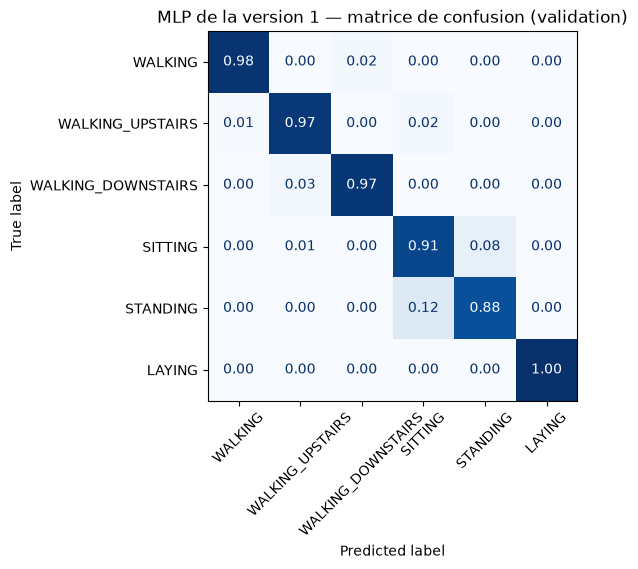

In [3]:
ACTIVATIONS = {"relu": nn.ReLU, "sigmoid": nn.Sigmoid, "tanh": nn.Tanh}
OPTIMIZERS = {
    "SGD":          lambda p, lr: torch.optim.SGD(p, lr=lr),
    "SGD+momentum": lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=0.9),
    "Adam":         lambda p, lr: torch.optim.Adam(p, lr=lr),
}

class MLP1(nn.Module):
    def __init__(self, input_dim=561, hidden_dim=64, output_dim=6, activation="relu"):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.act = ACTIVATIONS[activation]()
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def hidden(self, x):
        return self.act(self.fc1(x))

    def forward(self, x):
        return self.fc2(self.hidden(x))

def train_epoch(model, loader, optimizer, lossfn, device):
    model.train()
    total_loss = 0.0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        loss = lossfn(model(X), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X.size(0)
    return total_loss / len(loader.dataset)

path = os.path.join(LOG_DIR, "v1_configuration_retenue.json")
if os.path.exists(path):
    with open(path) as f:
        cfg = json.load(f)
else:
    print("ATTENTION : exécutez d'abord V1_one_hidden_layer.ipynb ; configuration par défaut utilisée.")
    cfg = {"hidden_dim": 64, "activation": "relu", "optimizer": "Adam", "lr": 1e-3, "n_epochs": 50}
if os.environ.get("HAR_FAST") == "1":            # uniquement pour tester rapidement que le notebook s'exécute
    cfg["n_epochs"] = 6
print("configuration :", {k: cfg[k] for k in ("hidden_dim", "activation", "optimizer", "lr", "n_epochs")})

set_seed(0)                                                      # graine 0, comme le modèle analysé en V1
g = torch.Generator().manual_seed(0)
train_loader = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(ytr, dtype=torch.long)),
                          batch_size=64, shuffle=True, generator=g)
model = MLP1(hidden_dim=cfg["hidden_dim"], activation=cfg["activation"]).to(device)
optimizer = OPTIMIZERS[cfg["optimizer"]](model.parameters(), cfg["lr"])
lossfn = nn.CrossEntropyLoss()
for ep in range(cfg["n_epochs"]):
    train_epoch(model, train_loader, optimizer, lossfn, device)

model.eval()
with torch.no_grad():
    Xva_t = torch.tensor(Xva).to(device)
    H_va = model.hidden(Xva_t).cpu().numpy()                     # activations de la couche cachée
    yva_pred = model(Xva_t).argmax(dim=1).cpu().numpy()
print(f"validation : accuracy {accuracy_score(yva, yva_pred):.4f} | F1 macro {f1_score(yva, yva_pred, average='macro'):.4f}")
print("entrées :", Xva.shape, "| couche cachée :", H_va.shape)

cm_val = confusion_matrix(yva, yva_pred, normalize="true")
ConfusionMatrixDisplay(cm_val, display_labels=CLASSES).plot(cmap="Blues", colorbar=False, values_format=".2f",
                                                            xticks_rotation=45)
plt.title("MLP de la version 1 — matrice de confusion (validation)"); save_fig("p6_confusion_val")

---
## Partie 1 — Lectures : t-SNE et UMAP (partie 6.1)

**t-SNE** (*t-distributed Stochastic Neighbor Embedding*, van der Maaten et Hinton, 2008).
1. Dans l'espace d'origine, on transforme les distances en **probabilités de voisinage** : $p_{j|i}$ est grand si
   $x_j$ est proche de $x_i$ (noyau gaussien). La largeur du noyau est choisie, pour chaque point, de façon à obtenir
   une **perplexité** donnée : c'est, en gros, le nombre effectif de voisins pris en compte.
2. En 2D, on définit des probabilités $q_{ij}$ avec un noyau de **Student** (à queues lourdes), puis on déplace les
   points pour minimiser la divergence de Kullback-Leibler $\mathrm{KL}(P\,\|\,Q)$ par **descente de gradient**.
   Les queues lourdes écartent les groupes et évitent qu'ils s'entassent au centre.

t-SNE conserve surtout la **structure locale** (qui est voisin de qui). Les **tailles** des groupes et les
**distances entre groupes** sur la figure n'ont pas de sens précis.

**UMAP** (*Uniform Manifold Approximation and Projection*, McInnes et al., 2018). On construit le graphe des $k$ plus
proches voisins (`n_neighbors`), pondéré, puis on cherche une disposition 2D qui conserve ce graphe (entropie croisée
entre graphes « flous »). UMAP est plus rapide que t-SNE et conserve souvent un peu mieux la structure globale ;
`n_neighbors` règle le compromis local/global, `min_dist` la compacité des groupes.

**Limites communes** :
- le résultat dépend des **hyperparamètres** (perplexité, `n_neighbors`) ;
- l'optimisation est **stochastique** : deux exécutions ne donnent pas la même figure ;
- une projection 2D peut **mélanger** des classes séparables en dimension élevée, ou faire apparaître des groupes
  artificiels ;
- ce sont des outils de **visualisation**, pas des mesures : toute conclusion doit être vérifiée autrement (partie 3).

**Question 1.1** — Pourquoi ne peut-on pas comparer la distance entre deux groupes sur une figure t-SNE ? Quel
paramètre de t-SNE joue un rôle analogue à `n_neighbors` d'UMAP ?

*Réponse :*

---
## Partie 2 — Projections : entrées brutes et couche cachée (partie 6.2)

On projette les **mêmes** fenêtres de validation, avec les **mêmes** paramètres, dans deux représentations :
les 561 variables d'entrée standardisées, et les activations de la couche cachée. Seule la représentation change.

deux t-SNE en 18 s


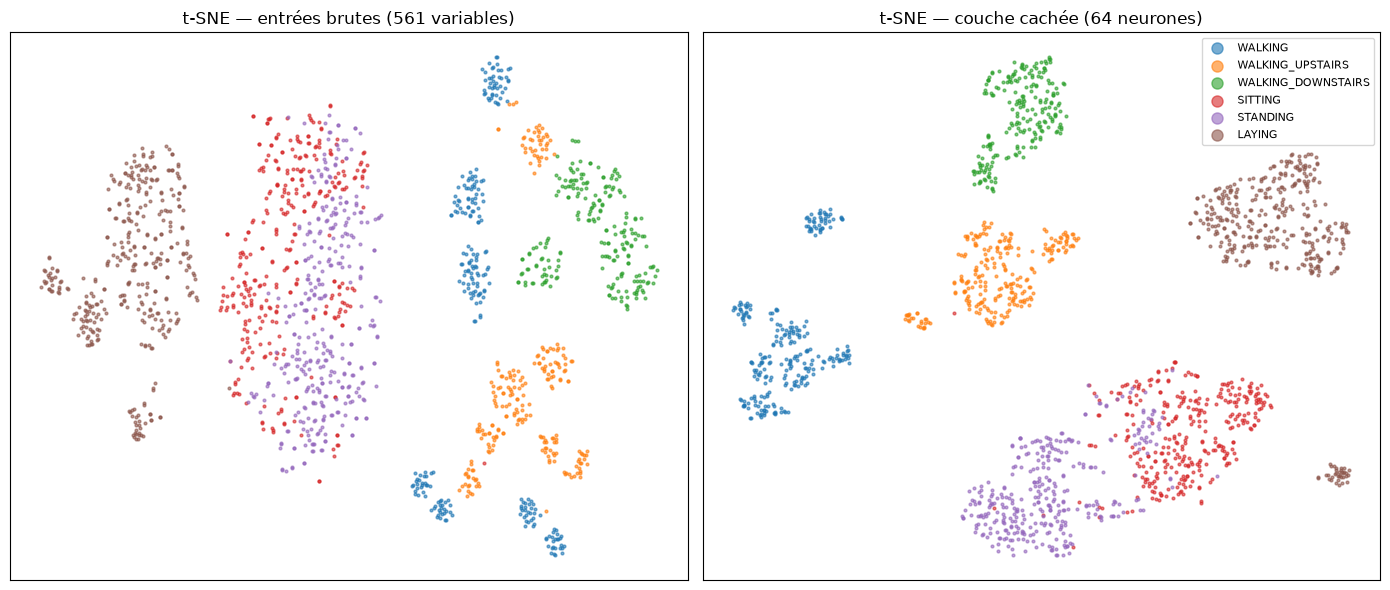

In [4]:
def projection(Z, method="tsne", seed=0, perplexity=30, n_neighbors=15, init="pca"):
    if method == "tsne":
        return TSNE(n_components=2, perplexity=perplexity, init=init, learning_rate="auto",
                    random_state=seed).fit_transform(Z)
    return umap.UMAP(n_components=2, n_neighbors=n_neighbors, min_dist=0.1, random_state=seed).fit_transform(Z)

def scatter_classes(Z, y, ax, title):
    for k, c in enumerate(CLASSES):
        ax.scatter(Z[y == k, 0], Z[y == k, 1], s=4, alpha=0.6, label=c)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

t0 = time.time()
Z_in_tsne = projection(Xva, "tsne")
Z_hid_tsne = projection(H_va, "tsne")
print(f"deux t-SNE en {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
scatter_classes(Z_in_tsne, yva, axes[0], f"t-SNE — entrées brutes ({Xva.shape[1]} variables)")
scatter_classes(Z_hid_tsne, yva, axes[1], f"t-SNE — couche cachée ({H_va.shape[1]} neurones)")
axes[1].legend(markerscale=4, fontsize=8)
plt.tight_layout(); save_fig("p6_tsne_entrees_vs_couche_cachee")

C:\Users\HP\Desktop\M2_DL_HAR\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\HP\Desktop\M2_DL_HAR\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\HP\Desktop\M2_DL_HAR\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a futur

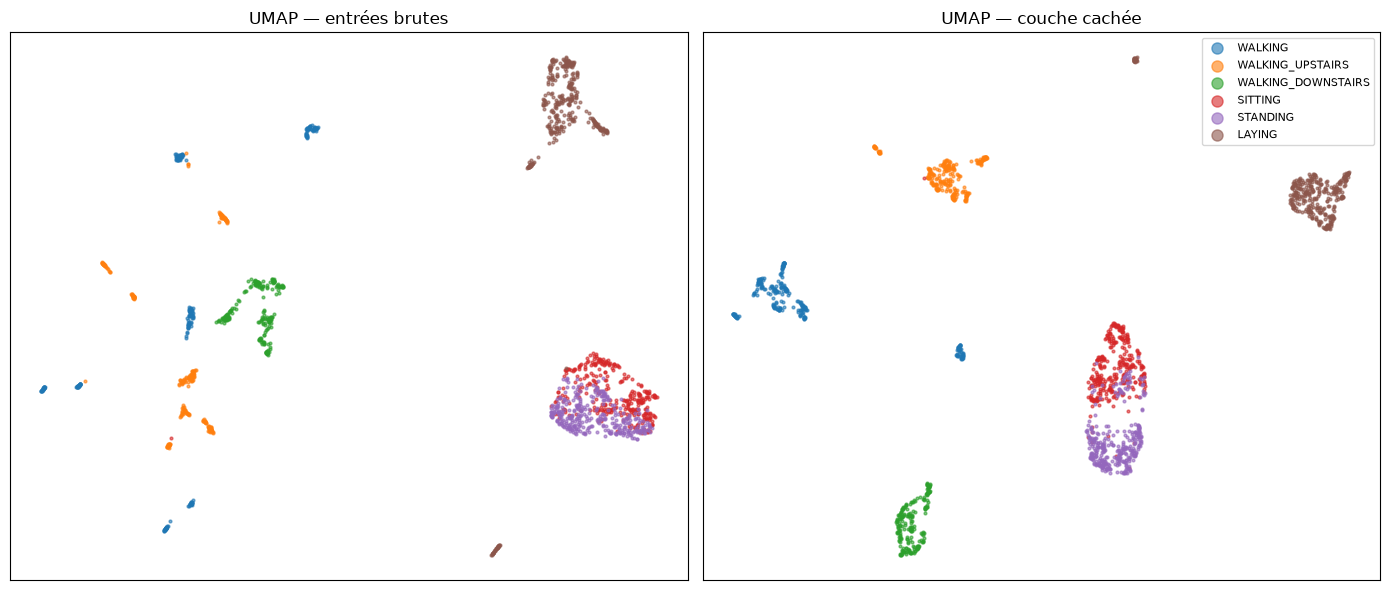

In [5]:
if UMAP_OK:
    Z_in_umap, Z_hid_umap = projection(Xva, "umap"), projection(H_va, "umap")
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    scatter_classes(Z_in_umap, yva, axes[0], "UMAP — entrées brutes")
    scatter_classes(Z_hid_umap, yva, axes[1], "UMAP — couche cachée")
    axes[1].legend(markerscale=4, fontsize=8)
    plt.tight_layout(); save_fig("p6_umap_entrees_vs_couche_cachee")
else:
    print("UMAP non installé : seule la t-SNE est présentée.")

**Question 2.1** — Dans l'espace des entrées, quels grands ensembles distingue-t-on ? Quelles activités se
mélangent ? Dans la couche cachée, les six activités forment-elles des groupes plus nets ? t-SNE et UMAP donnent-ils
la même lecture ?

*Réponse :*

---
## Partie 3 — Mesurer la séparation des classes sans passer par la figure

Pour ne pas conclure sur une impression visuelle (partie 1, limites), on mesure la séparation des classes
**dans chaque espace**, y compris en dimension d'origine :
- le **coefficient de silhouette** (entre −1 et 1) : pour chaque point, compare la distance moyenne à sa classe et
  à la classe la plus proche ; plus il est grand, mieux les classes sont séparées ;
- la **pureté des 10 plus proches voisins** : proportion des 10 voisins d'une fenêtre qui ont la même activité.

In [6]:
def neighbour_mixing(Z, y, k=10):
    # M[i, j] = part des k plus proches voisins des fenêtres de la classe i qui appartiennent à la classe j.
    idx = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]   # sans le point lui-même
    M = np.zeros((len(CLASSES), len(CLASSES)))
    for i in range(len(CLASSES)):
        M[i] = np.bincount(y[idx[y == i]].ravel(), minlength=len(CLASSES)) / (k * (y == i).sum())
    return M

spaces = {"entrées (561 dim.)": Xva, "couche cachée": H_va, "t-SNE des entrées": Z_in_tsne, "t-SNE de la couche cachée": Z_hid_tsne}
if UMAP_OK:
    spaces.update({"UMAP des entrées": Z_in_umap, "UMAP de la couche cachée": Z_hid_umap})
separation = pd.DataFrame({name: {"silhouette": silhouette_score(Z, yva),
                                  "pureté 10-NN": np.diag(neighbour_mixing(Z, yva)) @ np.bincount(yva) / len(yva)}
                           for name, Z in spaces.items()}).T
separation.round(3)

,silhouette,pureté 10-NN
entrées (561 dim.),0.060,0.912
couche cachée,0.383,0.957
t-SNE des entrées,0.258,0.937
t-SNE de la couche cachée,0.531,0.958
UMAP des entrées,0.257,0.911
UMAP de la couche cachée,0.639,0.953


**Question 3.1** — La couche cachée sépare-t-elle mieux les activités que l'espace des entrées ? Les valeurs calculées
sur les projections 2D sont-elles proches de celles calculées en dimension d'origine ? Qu'en conclure sur la
fidélité des figures ?

*Réponse :*

---
## Partie 4 — Chevauchements et matrice de confusion (partie 6.3)

Les classes qui se **chevauchent** dans la représentation sont-elles celles que le modèle **confond** ? On compare,
pour chaque paire de classes $(i, j)$ :
- la part des 10 plus proches voisins des fenêtres de la classe $i$ qui sont de la classe $j$ (dans la couche cachée) ;
- le taux de fenêtres de la classe $i$ prédites $j$ (matrice de confusion normalisée par ligne).

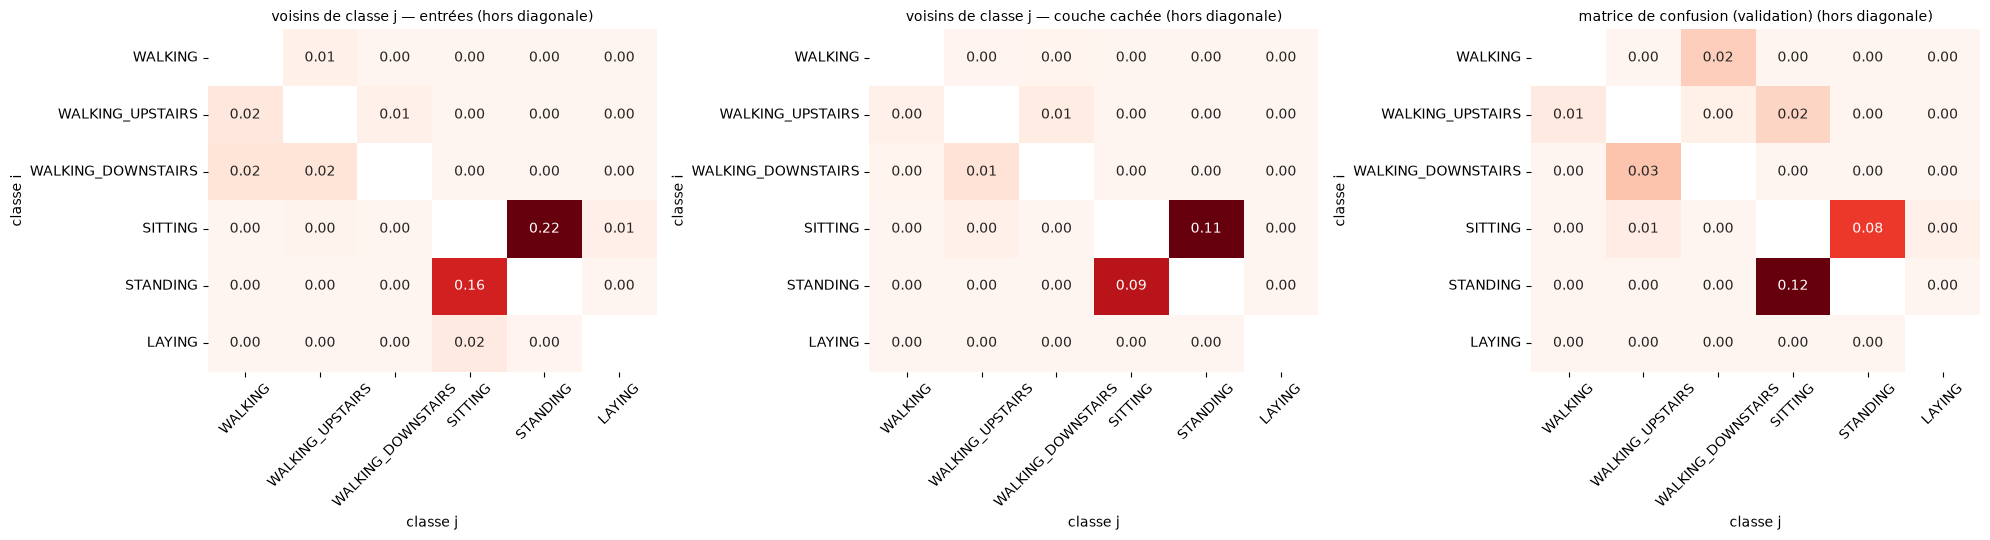

,classe i,classe j,confusion i→j,voisins j (couche cachée),voisins j (entrées)
0,STANDING,SITTING,0.125,0.091,0.161
1,SITTING,STANDING,0.080,0.113,0.223
2,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS,0.027,0.012,0.022
3,WALKING,WALKING_DOWNSTAIRS,0.023,0.001,0.000
4,WALKING_UPSTAIRS,SITTING,0.020,0.000,0.000
5,WALKING_UPSTAIRS,WALKING,0.008,0.003,0.019
6,SITTING,WALKING_UPSTAIRS,0.006,0.003,0.003
7,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,0.004,0.006,0.005


corrélation (30 paires) entre la confusion et « voisins j (couche cachée) » : 0.92
corrélation (30 paires) entre la confusion et « voisins j (entrées) » : 0.89


In [7]:
M_in, M_hid = neighbour_mixing(Xva, yva), neighbour_mixing(H_va, yva)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, (M, titre) in zip(axes, [(M_in, "voisins de classe j — entrées"), (M_hid, "voisins de classe j — couche cachée"),
                                 (cm_val, "matrice de confusion (validation)")]):
    sns.heatmap(M, mask=np.eye(len(CLASSES), dtype=bool), annot=True, fmt=".2f", cmap="Reds", vmin=0, cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)        # diagonale masquée : on ne montre que les « erreurs »
    ax.set_title(titre + " (hors diagonale)", fontsize=10); ax.set_xlabel("classe j"); ax.set_ylabel("classe i")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); save_fig("p6_chevauchements_vs_confusion")

paires = pd.DataFrame([{"classe i": CLASSES[i], "classe j": CLASSES[j], "confusion i→j": cm_val[i, j],
                        "voisins j (couche cachée)": M_hid[i, j], "voisins j (entrées)": M_in[i, j]}
                       for i in range(6) for j in range(6) if i != j])
paires = paires.sort_values("confusion i→j", ascending=False).reset_index(drop=True)
display(paires.head(8).round(3))
for col in ["voisins j (couche cachée)", "voisins j (entrées)"]:
    r = np.corrcoef(paires["confusion i→j"], paires[col])[0, 1] if paires["confusion i→j"].std() > 0 else float("nan")
    print(f"corrélation (30 paires) entre la confusion et « {col} » : {r:.2f}")

**Question 4.1** — Les paires de classes qui se chevauchent dans la couche cachée correspondent-elles aux paires les
plus confondues ? Lesquelles ? La confusion est-elle plausible du point de vue des capteurs (téléphone à la ceinture :
que mesure-t-il quand la personne est assise ou debout, immobile ?).

**Question 4.2** — Qu'est-ce que le réseau a changé par rapport à l'espace des entrées ? Pour quelles paires de classes
le chevauchement a-t-il le plus diminué ? Qu'en déduire sur ce que la couche cachée a appris ?

*Réponse :*

---
## Partie 5 — Limites : perplexité et variabilité d'une exécution à l'autre (partie 6.3)

### 5.1 Effet de la perplexité

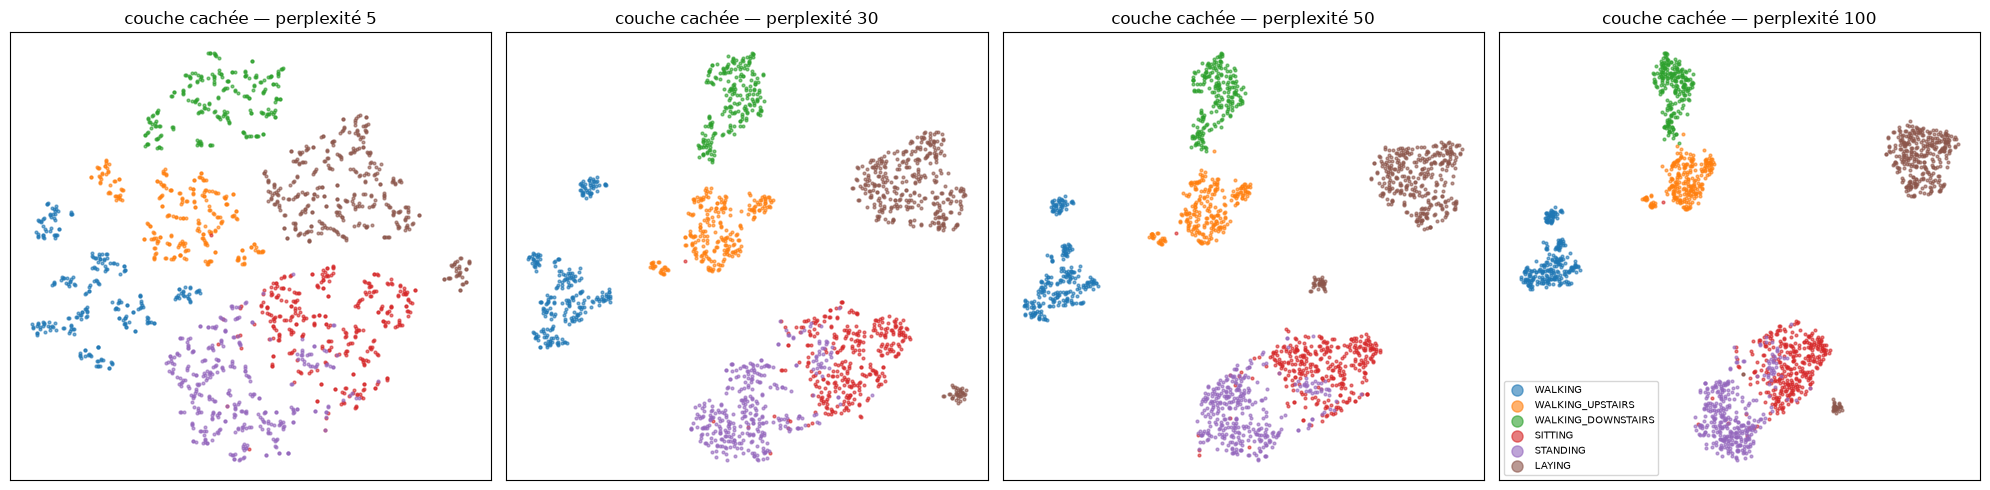

In [8]:
perplexites = [5, 30, 50, 100]
fig, axes = plt.subplots(1, len(perplexites), figsize=(5 * len(perplexites), 5))
for ax, p in zip(axes, perplexites):
    scatter_classes(projection(H_va, "tsne", perplexity=p), yva, ax, f"couche cachée — perplexité {p}")
axes[-1].legend(markerscale=4, fontsize=7)
plt.tight_layout(); save_fig("p6_tsne_perplexite")

### 5.2 Variabilité d'une exécution à l'autre
Même représentation, même perplexité (30), trois graines différentes. Par défaut, t-SNE part d'une ACP
(`init="pca"`), ce qui rend le résultat presque déterministe ; pour voir la variabilité propre à l'optimisation, on
part ici d'une position **aléatoire** (`init="random"`). On mesure aussi la pureté des 10 plus proches voisins.

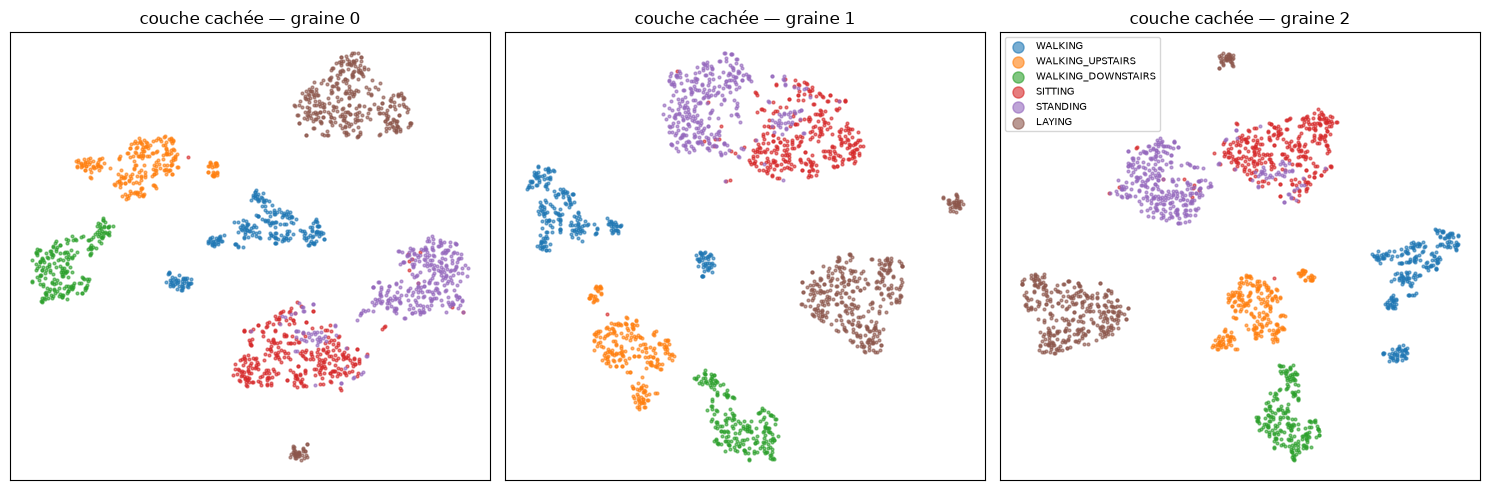

pureté 10-NN des trois projections : 0.957 ± 0.001


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
purete = []
for ax, seed in zip(axes, [0, 1, 2]):
    Z = projection(H_va, "tsne", seed=seed, init="random")
    purete.append(np.diag(neighbour_mixing(Z, yva)) @ np.bincount(yva) / len(yva))
    scatter_classes(Z, yva, ax, f"couche cachée — graine {seed}")
axes[-1].legend(markerscale=4, fontsize=7)
plt.tight_layout(); save_fig("p6_tsne_graines")
print(f"pureté 10-NN des trois projections : {np.mean(purete):.3f} ± {np.std(purete, ddof=1):.3f}")

**Question 5.1** — Comment la figure change-t-elle avec la perplexité ? Avec la graine ? Quels éléments restent
stables d'une figure à l'autre (ce sont les seuls que l'on peut interpréter) ? Quelles précautions faut-il prendre
pour présenter ces figures dans le rapport ?

*Réponse :*

---
## Partie 6 — Synthèse

**Exercice 6.1** — Rédigez en 5 à 8 lignes (pour la section « Interprétabilité » du rapport) :
- ce que la couche cachée a appris par rapport aux entrées (appuyé sur la partie 3) ;
- le lien entre chevauchements et confusions (partie 4), et l'explication du point de vue des capteurs ;
- les limites de ces méthodes et les précautions prises (partie 5).

*Réponse :*